# Hospital Operations & Patient Experience Analytics
## Beginner-Friendly End-to-End Healthcare Analytics Project

### Business Goal
The hospital wants to understand:
- Who are our patients?
- Which departments are overloaded?
- Where are waiting-time problems happening?
- Does waiting time affect satisfaction?
- Which patient groups use the hospital more often?
- Which service types and payer groups create the highest financial burden?
- What actions should management take?

### How We Will Work
For every analysis we follow the same analyst workflow:

**Business Problem → Analysis → Result → Observation → Insight → Recommendation**

The recommendation is written **only after looking at the result**.


## 1. Import Libraries


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', None)


## 2. Load the Data


In [5]:
patients = pd.read_csv('patients.csv')
visits = pd.read_csv('visits.csv')
billing = pd.read_csv('billing.csv')

print('Patients:', patients.shape)
print('Visits:', visits.shape)
print('Billing:', billing.shape)


Patients: (4010, 10)
Visits: (12015, 10)
Billing: (12015, 9)


## 3. Basic Data Understanding

### Business Purpose
Before cleaning, first understand:
- number of rows and columns
- data types
- missing values
- duplicate records


In [3]:
print('\nPATIENTS')
display(patients.head())
patients.info()

print('\nVISITS')
display(visits.head())
visits.info()

print('\nBILLING')
display(billing.head())
billing.info()



PATIENTS


,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date
0,100001,Patient_100001,Male,39,Hyderabad,NaN,Insured,NaN,30.9,2023-11-20
1,100002,Patient_100002,Male,49,Hyderabad,A+,Government Scheme,Thyroid,18.4,2023-07-04
2,100003,Patient_100003,Female,23,Karimnagar,B+,Insured,NaN,17.8,2022-06-24
3,100004,Patient_100004,female,52,Secunderabad,O+,Insured,Cardiac,20.4,2025-10-18
4,100005,Patient_100005,Male,41,Nizamabad,O-,Insured,Diabetes,21.5,2022-07-15


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4010 entries, 0 to 4009
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         4010 non-null   int64  
 1   patient_name       4010 non-null   object 
 2   gender             4010 non-null   object 
 3   age                4010 non-null   int64  
 4   city               3961 non-null   object 
 5   blood_group        3969 non-null   object 
 6   insurance_status   4010 non-null   object 
 7   chronic_condition  2150 non-null   object 
 8   bmi                3930 non-null   float64
 9   registration_date  4010 non-null   object 
dtypes: float64(1), int64(2), object(7)
memory usage: 313.4+ KB

VISITS


,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12015 entries, 0 to 12014
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   visit_id              12015 non-null  int64  
 1   patient_id            12015 non-null  int64  
 2   visit_date            12015 non-null  object 
 3   visit_hour            12015 non-null  int64  
 4   department            11975 non-null  object 
 5   diagnosis             11895 non-null  object 
 6   visit_type            12015 non-null  object 
 7   waiting_time_minutes  11835 non-null  float64
 8   length_of_stay_days   12015 non-null  float64
 9   satisfaction_score    11855 non-null  float64
dtypes: float64(3), int64(3), object(4)
memory usage: 938.8+ KB

BILLING


,bill_id,visit_id,patient_id,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date
0,800001,500001,102866,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10
1,800002,500002,100602,1609.59,0.00,1609.59,Card,Paid,2025-01-23
2,800003,500003,102563,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04
3,800004,500004,102617,20186.36,14645.71,5540.65,UPI,Paid,2024-06-30
4,800005,500005,100435,3098.79,2117.99,980.80,UPI,Paid,2025-04-11


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12015 entries, 0 to 12014
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   bill_id                   12015 non-null  int64  
 1   visit_id                  12015 non-null  int64  
 2   patient_id                12015 non-null  int64  
 3   bill_amount               11865 non-null  float64
 4   insurance_covered_amount  11835 non-null  float64
 5   patient_paid_amount       11865 non-null  float64
 6   payment_method            11925 non-null  object 
 7   payment_status            12015 non-null  object 
 8   billing_date              12015 non-null  object 
dtypes: float64(3), int64(3), object(3)
memory usage: 844.9+ KB


In [6]:
# Replace blank text with NaN only in columns where blanks were intentionally created
patients[['bmi','city','blood_group']] = patients[['bmi','city','blood_group']].replace('', np.nan)

In [7]:
visits[['waiting_time_minutes','satisfaction_score','diagnosis','department']] =     visits[['waiting_time_minutes','satisfaction_score','diagnosis','department']].replace('', np.nan)
billing[['bill_amount','insurance_covered_amount','patient_paid_amount','payment_method']] =     billing[['bill_amount','insurance_covered_amount','patient_paid_amount','payment_method']].replace('', np.nan)


In [8]:
patients.isnull().sum()

patient_id              0
patient_name            0
gender                  0
age                     0
city                   49
blood_group            41
insurance_status        0
chronic_condition    1860
bmi                    80
registration_date       0
dtype: int64

In [9]:
visits.isnull().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department               40
diagnosis               120
visit_type                0
waiting_time_minutes    180
length_of_stay_days       0
satisfaction_score      160
dtype: int64

In [10]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 150
insurance_covered_amount    180
patient_paid_amount         150
payment_method               90
payment_status                0
billing_date                  0
dtype: int64

In [12]:
for table in [patients, billing, visits]:
    print("*********************************")
    print(table.isnull().sum())

*********************************
patient_id              0
patient_name            0
gender                  0
age                     0
city                   49
blood_group            41
insurance_status        0
chronic_condition    1860
bmi                    80
registration_date       0
dtype: int64
*********************************
bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 150
insurance_covered_amount    180
patient_paid_amount         150
payment_method               90
payment_status                0
billing_date                  0
dtype: int64
*********************************
visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department               40
diagnosis               120
visit_type                0
waiting_time_minutes    180
length_of_stay_days       0
satisfaction_score      160
dtype: int64


In [11]:
# Convert numeric columns back to numeric
patients['age'] = pd.to_numeric(patients['age'], errors='coerce')
patients['bmi'] = pd.to_numeric(patients['bmi'], errors='coerce')
visits['waiting_time_minutes'] = pd.to_numeric(visits['waiting_time_minutes'], errors='coerce')
visits['satisfaction_score'] = pd.to_numeric(visits['satisfaction_score'], errors='coerce')
visits['length_of_stay_days'] = pd.to_numeric(visits['length_of_stay_days'], errors='coerce')
billing['bill_amount'] = pd.to_numeric(billing['bill_amount'], errors='coerce')
billing['insurance_covered_amount'] = pd.to_numeric(billing['insurance_covered_amount'], errors='coerce')
billing['patient_paid_amount'] = pd.to_numeric(billing['patient_paid_amount'], errors='coerce')


## 4. Missing Values and Duplicate Audit


In [12]:
print('Patients missing values')
display(patients.isna().sum())

print('Visits missing values')
display(visits.isna().sum())

print('Billing missing values')
display(billing.isna().sum())

print('Patient duplicates:', patients.duplicated().sum())
print('Visit duplicates:', visits.duplicated().sum())
print('Billing duplicates:', billing.duplicated().sum())


Patients missing values


patient_id              0
patient_name            0
gender                  0
age                     0
city                   49
blood_group            41
insurance_status        0
chronic_condition    1860
bmi                    80
registration_date       0
dtype: int64

Visits missing values


visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department               40
diagnosis               120
visit_type                0
waiting_time_minutes    180
length_of_stay_days       0
satisfaction_score      160
dtype: int64

Billing missing values


bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 150
insurance_covered_amount    180
patient_paid_amount         150
payment_method               90
payment_status                0
billing_date                  0
dtype: int64

Patient duplicates: 10
Visit duplicates: 15
Billing duplicates: 15


# 5. Data Cleaning

We will keep the code simple.  
The main idea is to choose the cleaning method based on the relationship between columns instead of applying one rule everywhere.


## 5.1 Clean Patient Data

### Scenario 1 - Duplicate Rows
Exact duplicates can inflate patient counts, so remove them.


In [13]:
patients = patients.drop_duplicates()

### Scenario 2 - Standardize Gender and City

If `Male`, `M`, and `male` are treated as different categories, our reports become wrong.


In [16]:
patients['blood_group'].unique()

array([nan, 'A+', 'B+', 'O+', 'O-', 'AB-', 'A-', 'AB+', 'B-'],
      dtype=object)

In [17]:
patients['blood_group'].nunique()

8

In [14]:
list_of_string_col = ['gender', 'city', 'blood_group', 'insurance_status', 'chronic_condition']

for col in list_of_string_col:
    print("*****************************************")
    print("The unique values in the", col)
    print(patients[col].unique())

*****************************************
The unique values in the gender
['Male' 'Female' 'female' 'FEMALE' 'M']
*****************************************
The unique values in the city
['Hyderabad' 'Karimnagar' 'Secunderabad' 'Nizamabad' nan 'Warangal'
 'HYDERABAD' ' hyderabad ']
*****************************************
The unique values in the blood_group
[nan 'A+' 'B+' 'O+' 'O-' 'AB-' 'A-' 'AB+' 'B-']
*****************************************
The unique values in the insurance_status
['Insured' 'Government Scheme' 'Self Pay']
*****************************************
The unique values in the chronic_condition
[nan 'Thyroid' 'Cardiac' 'Diabetes' 'Hypertension' 'Asthma']


In [12]:
patients.head(3)

,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date
0,100001,Patient_100001,Male,39,Hyderabad,NaN,Insured,None,30.9,2023-11-20
1,100002,Patient_100002,Male,49,Hyderabad,A+,Government Scheme,Thyroid,18.4,2023-07-04
2,100003,Patient_100003,Female,23,Karimnagar,B+,Insured,None,17.8,2022-06-24


In [13]:
patients['city'].unique()

array(['Hyderabad', 'Karimnagar', 'Secunderabad', 'Nizamabad', nan,
       'Warangal', 'HYDERABAD', ' hyderabad '], dtype=object)

In [15]:
patients['gender'] = patients['gender'].replace({
    'M':'Male',
    'female':'Female',
    'FEMALE':'Female'
})


In [21]:
patients['gender'].unique()


array(['Male', 'Female'], dtype=object)

In [16]:
patients['city'] = patients['city'].str.strip().str.title()

In [23]:
patients['city'].unique()

array(['Hyderabad', 'Karimnagar', 'Secunderabad', 'Nizamabad', nan,
       'Warangal'], dtype=object)

### Scenario 3 - Invalid Age

Ages below 1 or above 100 are invalid for this project.

Instead of immediately using the overall median, check whether chronic-condition groups have different age patterns.


In [24]:
patients.loc[(patients['age'] < 1) | (patients['age'] > 100), 'age'] 

45      125
193      -4
1021    125
1050     -4
1421     -4
1684     -4
2697    125
2803     -4
2891    125
2915    125
3084    125
3085     -4
3169     -4
3969    125
Name: age, dtype: int64

In [17]:
patients.loc[(patients['age'] < 1) | (patients['age'] > 100), 'age'] = np.nan

In [26]:
patients.loc[(patients['age'] < 1) | (patients['age'] > 100), 'age'] 

Series([], Name: age, dtype: float64)

In [18]:
display(
    patients.groupby('chronic_condition')['age'].median().sort_values()
)

chronic_condition
Asthma          44.0
Thyroid         49.0
Diabetes        51.0
Hypertension    54.0
Cardiac         56.0
Name: age, dtype: float64

### Cleaning Decision

The chronic-condition groups show different age profiles, so we fill missing/invalid age using the median age of the same chronic-condition group.


In [28]:
patients['chronic_condition'].unique()

array([nan, 'Thyroid', 'Cardiac', 'Diabetes', 'Hypertension', 'Asthma'],
      dtype=object)

In [19]:
age_median = patients.groupby('chronic_condition')['age'].median()
age_median

chronic_condition
Asthma          44.0
Cardiac         56.0
Diabetes        51.0
Hypertension    54.0
Thyroid         49.0
Name: age, dtype: float64

In [30]:
age_median['Asthma']

np.float64(44.0)

In [31]:
mask = (
        patients['age'].isna() & patients['chronic_condition'].eq('Asthma')
    )

In [32]:
patients.loc[mask, 'age'] = 

2915   NaN
Name: age, dtype: float64

In [34]:
patients['chronic_condition'].unique()

array([nan, 'Thyroid', 'Cardiac', 'Diabetes', 'Hypertension', 'Asthma'],
      dtype=object)

In [20]:
age_median = patients.groupby('chronic_condition')['age'].median()

for condition in ['Thyroid', 'Cardiac', 'Diabetes', 'Hypertension', 'Asthma']:
    value = age_median[condition]

    mask = (
        patients['age'].isna() & patients['chronic_condition'].eq(condition)
    )

    patients.loc[mask, 'age'] = value

In [36]:
patients['age'].isnull().sum()

np.int64(9)

In [21]:
# of we still have the missing vlaues then use the overall ,edain tp replace the missing vlaues 

patients['age'] = patients['age'].fillna(patients['age'].median())
patients['age'] = patients['age'].round().astype(int)

In [22]:
patients['age'].isnull().sum()

np.int64(0)

In [39]:
patients.isnull().sum()

patient_id              0
patient_name            0
gender                  0
age                     0
city                   49
blood_group            40
insurance_status        0
chronic_condition    1856
bmi                    80
registration_date       0
dtype: int64

### Scenario 4 - Missing BMI

BMI may vary by age group.  
So first create age groups, then fill missing BMI using the median BMI of the same age group.


In [23]:
patients['age_group'] = pd.cut(
    patients['age'],
    bins = [0,17,30,45,60,100],
    labels=['0-17','18-30','31-45','46-60','60+']
)

In [41]:
patients.head()

,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group
0,100001,Patient_100001,Male,39,Hyderabad,NaN,Insured,NaN,30.9,2023-11-20,31-45
1,100002,Patient_100002,Male,49,Hyderabad,A+,Government Scheme,Thyroid,18.4,2023-07-04,46-60
2,100003,Patient_100003,Female,23,Karimnagar,B+,Insured,NaN,17.8,2022-06-24,18-30
3,100004,Patient_100004,Female,52,Secunderabad,O+,Insured,Cardiac,20.4,2025-10-18,46-60
4,100005,Patient_100005,Male,41,Nizamabad,O-,Insured,Diabetes,21.5,2022-07-15,31-45


In [42]:
patients.loc[(patients['bmi'] < 12) | (patients['bmi'] > 55), 'bmi']

Series([], Name: bmi, dtype: float64)

In [24]:
patients.loc[(patients['bmi'] < 12) | (patients['bmi'] > 55), 'bmi'] = np.nan

In [25]:
bmi_median = patients.groupby('age_group')['bmi'].median()
# cross check 
bmi_median

C:\Users\RajendraPrasad\AppData\Local\Temp\ipykernel_19144\2877716975.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bmi_median = patients.groupby('age_group')['bmi'].median()


age_group
0-17     25.2
18-30    25.9
31-45    25.6
46-60    25.6
60+      25.4
Name: bmi, dtype: float64

In [46]:
patients.loc[(patients['age_group'] == '0-17') & (patients['bmi'].isna()) ,'bmi']

473    NaN
1622   NaN
1969   NaN
3270   NaN
3517   NaN
3769   NaN
Name: bmi, dtype: float64

In [47]:
patients['age_group'].dropna()

0       31-45
1       46-60
2       18-30
3       46-60
4       31-45
        ...  
3995    46-60
3996    31-45
3997      60+
3998    46-60
3999    18-30
Name: age_group, Length: 4000, dtype: category
Categories (5, object): ['0-17' < '18-30' < '31-45' < '46-60' < '60+']

In [49]:
patients['age_group'].dropna().unique()

['31-45', '46-60', '18-30', '60+', '0-17']
Categories (5, object): ['0-17' < '18-30' < '31-45' < '46-60' < '60+']

In [50]:
bmi_median['0-17']

np.float64(25.2)

In [26]:
bmi_median = patients.groupby('age_group')['bmi'].median()

for group in patients['age_group'].dropna().unique():
    mask = (
        patients['bmi'].isna() &
        patients['age_group'].eq(group)
    )

    patients.loc[mask, 'bmi'] = bmi_median[group]

patients['bmi'] = patients['bmi'].fillna(patients['bmi'].median())


C:\Users\RajendraPrasad\AppData\Local\Temp\ipykernel_19144\2004093944.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bmi_median = patients.groupby('age_group')['bmi'].median()


In [52]:
patients.isnull().sum()


patient_id              0
patient_name            0
gender                  0
age                     0
city                   49
blood_group            40
insurance_status        0
chronic_condition    1856
bmi                     0
registration_date       0
age_group               0
dtype: int64

### Scenario 5 - City and Blood Group

We do not have enough evidence to correctly infer missing city or blood group.

So we use `Unknown` instead of inventing a value.


In [27]:
patients['city'] = patients['city'].fillna('Unknown')
patients['blood_group'] = patients['blood_group'].fillna('Unknown')

In [54]:
patients.isna().sum()

patient_id              0
patient_name            0
gender                  0
age                     0
city                    0
blood_group             0
insurance_status        0
chronic_condition    1856
bmi                     0
registration_date       0
age_group               0
dtype: int64

In [28]:
patients['registration_date'] = pd.to_datetime(patients['registration_date'], errors='coerce')

## 5.2 Clean Visit Data


In [29]:
visits = visits.drop_duplicates().copy()

In [58]:
cat_cols = ['department', 'diagnosis', 'visit_type']

for column in cat_cols:
    print("********************************")
    print("The unique values in the col", column)
    print(visits[column].unique())

********************************
The unique values in the col department
['General Medicine' 'Orthopedics' 'Gynecology' 'Cardiology' 'Pulmonology'
 'Pediatrics' 'ORTHOPEDICS' nan 'cardiology' ' GENERAL MEDICINE ']
********************************
The unique values in the col diagnosis
['Hypertension Review' 'Diabetes Review' 'Sports Injury' 'PCOS' 'Fever'
 'Viral Infection' 'Arrhythmia' 'Pregnancy Review' 'Pneumonia' 'Arthritis'
 'Coronary Artery Disease' 'Fracture' 'COPD' 'Menstrual Disorder' 'UTI'
 'Back Pain' 'Asthma' 'Allergy' 'Respiratory Infection' nan 'Hypertension'
 'Gastritis' 'Chest Pain' 'Gastroenteritis']
********************************
The unique values in the col visit_type
['Inpatient' 'OPD' 'Emergency']


In [30]:
visits['visit_date'] = pd.to_datetime(visits['visit_date'], errors='coerce')
visits['department'] = visits['department'].str.strip().str.title()


In [60]:
cat_cols = ['department', 'diagnosis', 'visit_type']

for column in cat_cols:
    print("********************************")
    print("The unique values in the col", column)
    print(visits[column].unique())

********************************
The unique values in the col department
['General Medicine' 'Orthopedics' 'Gynecology' 'Cardiology' 'Pulmonology'
 'Pediatrics' nan]
********************************
The unique values in the col diagnosis
['Hypertension Review' 'Diabetes Review' 'Sports Injury' 'PCOS' 'Fever'
 'Viral Infection' 'Arrhythmia' 'Pregnancy Review' 'Pneumonia' 'Arthritis'
 'Coronary Artery Disease' 'Fracture' 'COPD' 'Menstrual Disorder' 'UTI'
 'Back Pain' 'Asthma' 'Allergy' 'Respiratory Infection' nan 'Hypertension'
 'Gastritis' 'Chest Pain' 'Gastroenteritis']
********************************
The unique values in the col visit_type
['Inpatient' 'OPD' 'Emergency']


In [32]:
visits.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0


In [61]:
visits.loc[visits['waiting_time_minutes'] <= 0, 'waiting_time_minutes']

1330    -10.0
1915    -10.0
2181    -10.0
3958    -10.0
4009    -10.0
4351    -10.0
5181    -10.0
5470    -10.0
5790    -10.0
9290    -10.0
11266   -10.0
11761   -10.0
Name: waiting_time_minutes, dtype: float64

In [62]:
visits.loc[(visits['satisfaction_score'] < 1) | (visits['satisfaction_score'] > 5), 'satisfaction_score']

1274     7.0
4257     7.0
6084     7.0
6109     7.0
6870     7.0
8545     7.0
9528     7.0
10773    7.0
10860    7.0
11511    7.0
Name: satisfaction_score, dtype: float64

In [31]:
# Convert impossible values to missing first
visits.loc[visits['waiting_time_minutes'] <= 0, 'waiting_time_minutes'] = np.nan
visits.loc[(visits['satisfaction_score'] < 1) | (visits['satisfaction_score'] > 5), 'satisfaction_score'] = np.nan
visits.loc[visits['length_of_stay_days'] < 0, 'length_of_stay_days'] = np.nan


In [32]:
visits.isnull().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department               40
diagnosis               120
visit_type                0
waiting_time_minutes    192
length_of_stay_days       8
satisfaction_score      170
dtype: int64

### Scenario 6 - Missing Department

A diagnosis is related to the department treating it.

So for missing department values:
1. find the most common department for each diagnosis
2. use that department


In [66]:
visits['diagnosis'].unique()

array(['Hypertension Review', 'Diabetes Review', 'Sports Injury', 'PCOS',
       'Fever', 'Viral Infection', 'Arrhythmia', 'Pregnancy Review',
       'Pneumonia', 'Arthritis', 'Coronary Artery Disease', 'Fracture',
       'COPD', 'Menstrual Disorder', 'UTI', 'Back Pain', 'Asthma',
       'Allergy', 'Respiratory Infection', nan, 'Hypertension',
       'Gastritis', 'Chest Pain', 'Gastroenteritis'], dtype=object)

In [33]:
diagnosis_department = (
    visits.dropna(subset=['diagnosis','department'])
          .groupby('diagnosis')['department']
          .agg(lambda x: x.mode()[0])
)


In [68]:
diagnosis_department

diagnosis
Allergy                          Pediatrics
Arrhythmia                       Cardiology
Arthritis                       Orthopedics
Asthma                          Pulmonology
Back Pain                       Orthopedics
COPD                            Pulmonology
Chest Pain                       Cardiology
Coronary Artery Disease          Cardiology
Diabetes Review            General Medicine
Fever                      General Medicine
Fracture                        Orthopedics
Gastritis                  General Medicine
Gastroenteritis                  Pediatrics
Hypertension                     Cardiology
Hypertension Review        General Medicine
Menstrual Disorder               Gynecology
PCOS                             Gynecology
Pneumonia                       Pulmonology
Pregnancy Review                 Gynecology
Respiratory Infection           Pulmonology
Sports Injury                   Orthopedics
UTI                              Gynecology
Viral Infection       

In [34]:
mask = visits['department'].isna() & visits['diagnosis'].notna()

visits.loc[mask, 'department'] = visits.loc[mask, 'diagnosis'].map(diagnosis_department)

visits['department'] = visits['department'].fillna('Unknown')


In [35]:
visits.isna().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department                0
diagnosis               120
visit_type                0
waiting_time_minutes    192
length_of_stay_days       8
satisfaction_score      170
dtype: int64

### Scenario 7 - Missing Diagnosis

Use the most common diagnosis within the same department.


In [36]:
department_diagnosis = (
    visits.dropna(subset=['diagnosis'])
          .groupby('department')['diagnosis']
          .agg(lambda x: x.mode()[0])
)


In [37]:
department_diagnosis

department
Cardiology          Coronary Artery Disease
General Medicine                      Fever
Gynecology               Menstrual Disorder
Orthopedics                        Fracture
Pediatrics                          Allergy
Pulmonology                            COPD
Name: diagnosis, dtype: object

In [38]:
mask = visits['diagnosis'].isna()

visits.loc[mask, 'diagnosis'] = visits.loc[mask, 'department'].map(department_diagnosis)

visits['diagnosis'] = visits['diagnosis'].fillna('Unknown')


In [39]:
visits.isna().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department                0
diagnosis                 0
visit_type                0
waiting_time_minutes    192
length_of_stay_days       8
satisfaction_score      170
dtype: int64

In [75]:
# Day 1

### Scenario 8 - Missing Waiting Time

Waiting time depends on both department and visit type.

Example:
- Cardiology OPD may wait longer than Emergency.
- Pediatrics may have a different pattern.

So fill missing values using the median of the same department and visit type.


In [40]:
wait_median = visits.groupby(
    ['department','visit_type']
)['waiting_time_minutes'].median()

In [41]:
wait_median

department        visit_type
Cardiology        Emergency     48.0
                  Inpatient     56.0
                  OPD           60.0
General Medicine  Emergency     40.5
                  Inpatient     48.0
                  OPD           52.0
Gynecology        Emergency     28.0
                  Inpatient     33.0
                  OPD           39.0
Orthopedics       Emergency     29.0
                  Inpatient     38.0
                  OPD           42.5
Pediatrics        Emergency     23.0
                  Inpatient     32.0
                  OPD           36.0
Pulmonology       Emergency     36.0
                  Inpatient     42.0
                  OPD           46.0
Name: waiting_time_minutes, dtype: float64

In [42]:
visits['department'].unique()

array(['General Medicine', 'Orthopedics', 'Gynecology', 'Cardiology',
       'Pulmonology', 'Pediatrics'], dtype=object)

In [43]:
visits['visit_type'].unique()

array(['Inpatient', 'OPD', 'Emergency'], dtype=object)

In [44]:
for department in visits['department'].unique():
    for visit_type in visits['visit_type'].unique():

        value = wait_median.get((department, visit_type))

        mask = (
            visits['waiting_time_minutes'].isna() &
            visits['department'].eq(department) &
            visits['visit_type'].eq(visit_type)
        )

        visits.loc[mask, 'waiting_time_minutes'] = value

In [45]:
visits.isnull().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department                0
diagnosis                 0
visit_type                0
waiting_time_minutes      0
length_of_stay_days       8
satisfaction_score      170
dtype: int64

In [46]:
visits['waiting_time_minutes'] = visits['waiting_time_minutes'].fillna(visits['waiting_time_minutes'].median())

In [47]:
visits.isna().sum()

visit_id                  0
patient_id                0
visit_date                0
visit_hour                0
department                0
diagnosis                 0
visit_type                0
waiting_time_minutes      0
length_of_stay_days       8
satisfaction_score      170
dtype: int64

In [46]:
visits.shape

(12000, 10)

### Scenario 9 - Missing Satisfaction

Waiting experience influences satisfaction.

So:
1. create waiting-time bands
2. use median satisfaction for the same department and waiting band


In [48]:
visits['wait_band'] = pd.cut(
    visits['waiting_time_minutes'],
    bins=[0,20,40,60,100],
    labels=['<=20','21-40','41-60','60+']
)

In [49]:
visits.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,wait_band
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,41-60
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,41-60
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,21-40
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,21-40
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,21-40


In [50]:
satisfaction_median = visits.groupby(
    ['department','wait_band'])['satisfaction_score'].median()

satisfaction_median

C:\Users\RajendraPrasad\AppData\Local\Temp\ipykernel_19144\3924631001.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  satisfaction_median = visits.groupby(


department        wait_band
Cardiology        <=20         4.90
                  21-40        4.60
                  41-60        4.30
                  60+          4.10
General Medicine  <=20         4.80
                  21-40        4.60
                  41-60        4.30
                  60+          4.10
Gynecology        <=20         4.80
                  21-40        4.60
                  41-60        4.40
                  60+          4.15
Orthopedics       <=20         4.80
                  21-40        4.60
                  41-60        4.30
                  60+          4.10
Pediatrics        <=20         4.80
                  21-40        4.60
                  41-60        4.40
                  60+          4.20
Pulmonology       <=20         4.90
                  21-40        4.60
                  41-60        4.30
                  60+          4.20
Name: satisfaction_score, dtype: float64

In [51]:
for department in visits['department'].unique():
    for band in visits['wait_band'].dropna().unique():

        value = satisfaction_median.get((department, band))

        mask = (
            visits['satisfaction_score'].isna() &
            visits['department'].eq(department) &
            visits['wait_band'].eq(band)
        )

        visits.loc[mask, 'satisfaction_score'] = value

In [52]:
visits.isnull().sum()

visit_id                 0
patient_id               0
visit_date               0
visit_hour               0
department               0
diagnosis                0
visit_type               0
waiting_time_minutes     0
length_of_stay_days      8
satisfaction_score       3
wait_band               90
dtype: int64

In [53]:
visits['satisfaction_score'] = visits['satisfaction_score'].fillna(visits['satisfaction_score'].median())


In [54]:
# cross check 
visits.isnull().sum()

visit_id                 0
patient_id               0
visit_date               0
visit_hour               0
department               0
diagnosis                0
visit_type               0
waiting_time_minutes     0
length_of_stay_days      8
satisfaction_score       0
wait_band               90
dtype: int64

## 5.3 Clean Billing Data


In [55]:
billing = billing.drop_duplicates().copy()

billing['billing_date'] = pd.to_datetime(billing['billing_date'],errors='coerce')

In [56]:
billing.head()

,bill_id,visit_id,patient_id,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date
0,800001,500001,102866,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10
1,800002,500002,100602,1609.59,0.00,1609.59,Card,Paid,2025-01-23
2,800003,500003,102563,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04
3,800004,500004,102617,20186.36,14645.71,5540.65,UPI,Paid,2024-06-30
4,800005,500005,100435,3098.79,2117.99,980.80,UPI,Paid,2025-04-11


In [57]:
billing['payment_method'].unique()

array(['Scheme', 'Card', 'UPI', 'Cash', 'Insurance', nan], dtype=object)

In [58]:
billing['payment_method'] = billing['payment_method'].str.strip().str.title()


In [59]:
billing.loc[billing['bill_amount'] <= 0, 'bill_amount']

126    -500.0
626    -500.0
716    -500.0
6353   -500.0
6797   -500.0
6933   -500.0
8037   -500.0
9571   -500.0
Name: bill_amount, dtype: float64

In [60]:
billing.loc[billing['patient_paid_amount'] < 0, 'patient_paid_amount']

874     -100.0
2057    -100.0
2613    -100.0
5639    -100.0
5930    -100.0
7176    -100.0
9368    -100.0
10818   -100.0
Name: patient_paid_amount, dtype: float64

In [61]:
billing.loc[billing['bill_amount'] <= 0, 'bill_amount'] = np.nan
billing.loc[billing['patient_paid_amount'] < 0, 'patient_paid_amount'] = np.nan

In [62]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 158
insurance_covered_amount    180
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
dtype: int64

### Scenario 10 - Missing Bill Amount

Bill amount depends strongly on department and visit type.

We bring these two columns from Visits and use the median for the same service combination.


In [63]:
billing = billing.merge(
    visits[['visit_id','department','visit_type']],
    on = 'visit_id',
    how = 'left'
)

In [64]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                 158
insurance_covered_amount    180
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
department                    0
visit_type                    0
dtype: int64

In [65]:
bill_median = billing.groupby(
    ['department','visit_type']
)['bill_amount'].median()

bill_median

department        visit_type
Cardiology        Emergency      7637.890
                  Inpatient     32958.105
                  OPD            3748.830
General Medicine  Emergency      2566.115
                  Inpatient     23005.610
                  OPD            1308.235
Gynecology        Emergency      4539.935
                  Inpatient     26307.570
                  OPD            2345.100
Orthopedics       Emergency      6050.125
                  Inpatient     28386.435
                  OPD            3085.245
Pediatrics        Emergency      2888.870
                  Inpatient     22684.420
                  OPD            1409.850
Pulmonology       Emergency      4962.460
                  Inpatient     26927.060
                  OPD            2460.655
Name: bill_amount, dtype: float64

In [66]:
for department in billing['department'].unique():
    for visit_type in billing['visit_type'].unique():

        value = bill_median.get((department, visit_type))

        mask = (
            billing['bill_amount'].isna() &
            billing['department'].eq(department) &
            billing['visit_type'].eq(visit_type)
        )

        billing.loc[mask, 'bill_amount'] = value


In [67]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount    180
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
department                    0
visit_type                    0
dtype: int64

In [69]:
billing['bill_amount'] = billing['bill_amount'].fillna(billing['bill_amount'].median())

In [70]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount    180
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
department                    0
visit_type                    0
dtype: int64

In [71]:
billing.head(2)

,bill_id,visit_id,patient_id,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,department,visit_type
0,800001,500001,102866,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,General Medicine,Inpatient
1,800002,500002,100602,1609.59,0.00,1609.59,Card,Paid,2025-01-23,General Medicine,OPD


In [72]:
patients.head(2)

,patient_id,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group
0,100001,Patient_100001,Male,39,Hyderabad,Unknown,Insured,NaN,30.9,2023-11-20,31-45
1,100002,Patient_100002,Male,49,Hyderabad,A+,Government Scheme,Thyroid,18.4,2023-07-04,46-60


### Scenario 11 - Missing Insurance Coverage

Bring `insurance_status` from Patients.

Business rule:
- Self Pay → insurance coverage = 0
- Insured / Government Scheme → use the typical coverage percentage of the same payer group


In [73]:
billing = billing.merge(
    patients[['patient_id','insurance_status']],
    on = 'patient_id',
    how = 'left'
)

In [74]:
mask = (
    billing['insurance_covered_amount'].isna() &
    billing['insurance_status'].eq('Self Pay')
)

billing.loc[mask, 'insurance_covered_amount']

185     NaN
646     NaN
853     NaN
960     NaN
1400    NaN
         ..
10886   NaN
11248   NaN
11468   NaN
11491   NaN
11756   NaN
Name: insurance_covered_amount, Length: 61, dtype: float64

In [75]:
mask = (
    billing['insurance_covered_amount'].isna() &
    billing['insurance_status'].eq('Self Pay')
)

billing.loc[mask, 'insurance_covered_amount'] = 0


In [76]:
billing.isna().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount    119
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
department                    0
visit_type                    0
insurance_status              0
dtype: int64

In [77]:
billing['coverage_pct'] = (
    billing['insurance_covered_amount'] /
    billing['bill_amount']
)
billing.head()

,bill_id,visit_id,patient_id,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,department,visit_type,insurance_status,coverage_pct
0,800001,500001,102866,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,General Medicine,Inpatient,Government Scheme,0.776478
1,800002,500002,100602,1609.59,0.00,1609.59,Card,Paid,2025-01-23,General Medicine,OPD,Self Pay,0.000000
2,800003,500003,102563,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,Orthopedics,Inpatient,Government Scheme,0.837198
3,800004,500004,102617,20186.36,14645.71,5540.65,Upi,Paid,2024-06-30,Gynecology,Inpatient,Insured,0.725525
4,800005,500005,100435,3098.79,2117.99,980.80,Upi,Paid,2025-04-11,General Medicine,Emergency,Insured,0.683489


In [78]:
coverage_median = billing.groupby('insurance_status')['coverage_pct'].median()

coverage_median

insurance_status
Government Scheme    0.824290
Insured              0.684064
Self Pay             0.000000
Name: coverage_pct, dtype: float64

In [79]:
1000 * 0.20

200.0

In [80]:
for payer in ['Insured','Government Scheme']:

    mask = (
        billing['insurance_covered_amount'].isna() &
        billing['insurance_status'].eq(payer)
    )

    billing.loc[mask, 'insurance_covered_amount'] = (
        billing.loc[mask, 'bill_amount'] * coverage_median[payer]
    )

billing['insurance_covered_amount'] = billing['insurance_covered_amount'].fillna(0)


In [81]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount      0
patient_paid_amount         158
payment_method               90
payment_status                0
billing_date                  0
department                    0
visit_type                    0
insurance_status              0
coverage_pct                119
dtype: int64

### Scenario 12 - Missing Patient Paid Amount

This value can be calculated directly:

`Patient Paid = Total Bill - Insurance Covered`

This is better than using mean or median.


In [82]:
mask = billing['patient_paid_amount'].isna()

billing.loc[mask, 'patient_paid_amount']

21      NaN
71      NaN
104     NaN
138     NaN
180     NaN
         ..
11675   NaN
11814   NaN
11827   NaN
11859   NaN
11883   NaN
Name: patient_paid_amount, Length: 158, dtype: float64

In [83]:
mask = billing['patient_paid_amount'].isna()

billing.loc[mask, 'patient_paid_amount'] = (
    billing.loc[mask, 'bill_amount'] -
    billing.loc[mask, 'insurance_covered_amount']
)

billing['patient_paid_amount'] = billing['patient_paid_amount'].clip(lower=0)


In [84]:
billing.isnull().sum()

bill_id                       0
visit_id                      0
patient_id                    0
bill_amount                   0
insurance_covered_amount      0
patient_paid_amount           0
payment_method               90
payment_status                0
billing_date                  0
department                    0
visit_type                    0
insurance_status              0
coverage_pct                119
dtype: int64

## 6. Merge the Three Tables

Visits is our main transaction table.


In [85]:
df = visits.merge(
    patients,
    on='patient_id',
    how='left'
)

In [86]:
df.columns

Index(['visit_id', 'patient_id', 'visit_date', 'visit_hour', 'department',
       'diagnosis', 'visit_type', 'waiting_time_minutes',
       'length_of_stay_days', 'satisfaction_score', 'wait_band',
       'patient_name', 'gender', 'age', 'city', 'blood_group',
       'insurance_status', 'chronic_condition', 'bmi', 'registration_date',
       'age_group'],
      dtype='object')

In [87]:
df = df.merge(
    billing[
        ['visit_id','patient_id','bill_amount',
         'insurance_covered_amount','patient_paid_amount',
         'payment_method','payment_status','billing_date']
    ],
    on = ['visit_id','patient_id'],
    how='left'
)

print(df.shape)
display(df.head())


(12000, 27)


,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,wait_band,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,41-60,Patient_102866,Male,27,Warangal,A+,Government Scheme,NaN,28.8,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,41-60,Patient_100602,Female,69,Nizamabad,B-,Self Pay,NaN,17.0,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,21-40,Patient_102563,Male,52,Warangal,B-,Government Scheme,NaN,24.3,2025-01-18,46-60,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,21-40,Patient_102617,Male,41,Secunderabad,O+,Insured,NaN,25.3,2023-10-10,31-45,20186.36,14645.71,5540.65,Upi,Paid,2024-06-30
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,21-40,Patient_100435,Female,47,Secunderabad,O-,Insured,Asthma,28.2,2025-03-04,46-60,3098.79,2117.99,980.80,Upi,Paid,2025-04-11


## 7. Feature Engineering


In [88]:
df['visit_day'] = df['visit_date'].dt.day_name()
df.head(2)

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,wait_band,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_day
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,41-60,Patient_102866,Male,27,Warangal,A+,Government Scheme,NaN,28.8,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,Friday
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,41-60,Patient_100602,Female,69,Nizamabad,B-,Self Pay,NaN,17.0,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23,Wednesday


In [89]:
df['visit_month'] = df['visit_date'].dt.to_period('M').astype(str)
# cross check 
df.head(3)

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,wait_band,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_day,visit_month
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,41-60,Patient_102866,Male,27,Warangal,A+,Government Scheme,NaN,28.8,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,Friday,2025-03
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,41-60,Patient_100602,Female,69,Nizamabad,B-,Self Pay,NaN,17.0,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23,Wednesday,2025-01
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,21-40,Patient_102563,Male,52,Warangal,B-,Government Scheme,NaN,24.3,2025-01-18,46-60,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,Tuesday,2024-06


In [90]:
df['visit_time_band'] = pd.cut(
    df['visit_hour'],
    bins=[0,6,11,16,20,24],
    labels=['Night','Morning','Midday','Evening','Late Evening'],
    right=False
)

In [91]:
df.head(2)

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,wait_band,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_day,visit_month,visit_time_band
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,41-60,Patient_102866,Male,27,Warangal,A+,Government Scheme,NaN,28.8,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,Friday,2025-03,Midday
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,41-60,Patient_100602,Female,69,Nizamabad,B-,Self Pay,NaN,17.0,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23,Wednesday,2025-01,Midday


In [92]:
df['out_of_pocket_pct'] = (
    df['patient_paid_amount'] / df['bill_amount'] * 100).round(1)

# cross chekc 
df.head(2)

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,wait_band,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_day,visit_month,visit_time_band,out_of_pocket_pct
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,41-60,Patient_102866,Male,27,Warangal,A+,Government Scheme,NaN,28.8,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,Friday,2025-03,Midday,22.4
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,41-60,Patient_100602,Female,69,Nizamabad,B-,Self Pay,NaN,17.0,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23,Wednesday,2025-01,Midday,100.0


In [93]:
df['high_wait_flag'] = np.where(df['waiting_time_minutes'] > 60,'High Wait','Normal Wait')

In [94]:
patient_visit_count = df.groupby(
    'patient_id'
)['visit_id'].transform('count')
patient_visit_count

0        6
1        3
2        2
3        5
4        2
        ..
11995    2
11996    3
11997    2
11998    3
11999    7
Name: visit_id, Length: 12000, dtype: int64

In [95]:
df['repeat_patient'] = np.where(
    patient_visit_count > 1,
    'Repeat',
    'Single Visit'
)


In [96]:
df.head()

,visit_id,patient_id,visit_date,visit_hour,department,diagnosis,visit_type,waiting_time_minutes,length_of_stay_days,satisfaction_score,wait_band,patient_name,gender,age,city,blood_group,insurance_status,chronic_condition,bmi,registration_date,age_group,bill_amount,insurance_covered_amount,patient_paid_amount,payment_method,payment_status,billing_date,visit_day,visit_month,visit_time_band,out_of_pocket_pct,high_wait_flag,repeat_patient
0,500001,102866,2025-03-07,11,General Medicine,Hypertension Review,Inpatient,44.0,1.0,4.7,41-60,Patient_102866,Male,27,Warangal,A+,Government Scheme,NaN,28.8,2025-02-19,18-30,7949.60,6172.69,1776.91,Scheme,Paid,2025-03-10,Friday,2025-03,Midday,22.4,Normal Wait,Repeat
1,500002,100602,2025-01-22,13,General Medicine,Diabetes Review,OPD,60.0,0.0,4.4,41-60,Patient_100602,Female,69,Nizamabad,B-,Self Pay,NaN,17.0,2022-02-12,60+,1609.59,0.00,1609.59,Card,Paid,2025-01-23,Wednesday,2025-01,Midday,100.0,Normal Wait,Repeat
2,500003,102563,2024-06-04,16,Orthopedics,Sports Injury,Inpatient,28.0,3.0,5.0,21-40,Patient_102563,Male,52,Warangal,B-,Government Scheme,NaN,24.3,2025-01-18,46-60,26915.56,22533.66,4381.90,Scheme,Partially Paid,2024-06-04,Tuesday,2024-06,Evening,16.3,Normal Wait,Repeat
3,500004,102617,2024-06-29,7,Gynecology,PCOS,Inpatient,27.0,4.0,5.0,21-40,Patient_102617,Male,41,Secunderabad,O+,Insured,NaN,25.3,2023-10-10,31-45,20186.36,14645.71,5540.65,Upi,Paid,2024-06-30,Saturday,2024-06,Morning,27.4,Normal Wait,Repeat
4,500005,100435,2025-04-08,15,General Medicine,Fever,Emergency,37.0,0.0,5.0,21-40,Patient_100435,Female,47,Secunderabad,O-,Insured,Asthma,28.2,2025-03-04,46-60,3098.79,2117.99,980.80,Upi,Paid,2025-04-11,Tuesday,2025-04,Midday,31.7,Normal Wait,Repeat


In [82]:
df['chronic_condition'].unique()

array(['None', 'Asthma', 'Hypertension', 'Diabetes', 'Thyroid', 'Cardiac'],
      dtype=object)

# PART A - UNIVARIATE ANALYSIS

Univariate analysis studies **one variable at a time**.
We first understand the distribution, then decide whether the result matters to the business.


## Analysis 1 - Which age group uses the hospital the most?


In [97]:
age_analysis = df['age_group'].value_counts().sort_index()
display(age_analysis)

age_group
0-17      545
18-30    1583
31-45    3488
46-60    3706
60+      2678
Name: count, dtype: int64

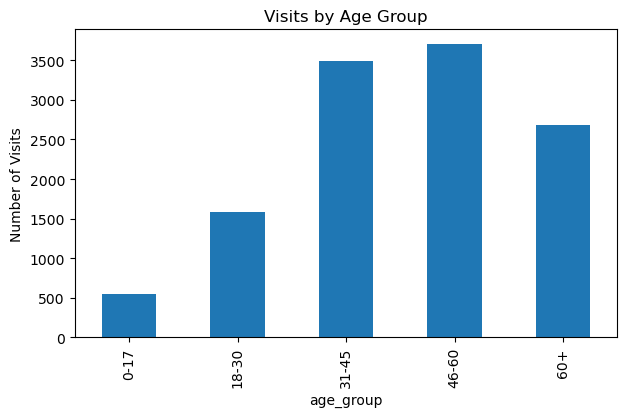

In [98]:
plt.figure(figsize=(7,4))
age_analysis.plot(kind='bar')
plt.title('Visits by Age Group')
plt.ylabel('Number of Visits')
plt.show()

### Observation
The **46-60** age group contributes the highest number of visits, with approximately **3,682 visits**.

### Insight
Middle-aged and older adults form an important part of hospital demand.

### Business Recommendation
Ensure chronic-care and preventive-health services are sufficiently available for the high-utilization age groups.


## Analysis 2 - What are the most common chronic conditions?


In [99]:
chronic_analysis = df['chronic_condition'].value_counts()
display(chronic_analysis)

chronic_condition
Hypertension    2226
Diabetes        1944
Asthma           906
Cardiac          816
Thyroid          657
Name: count, dtype: int64

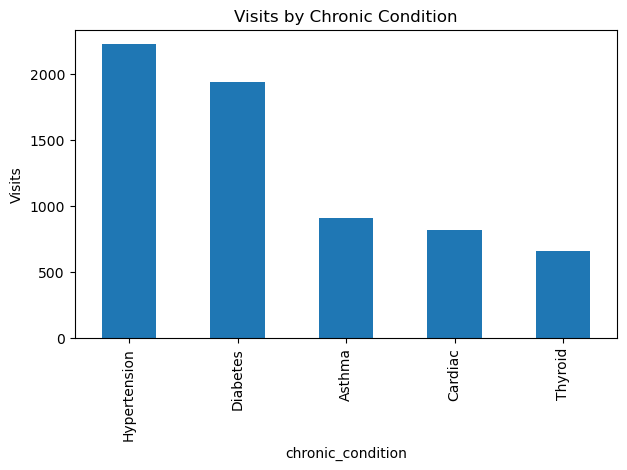

In [100]:
plt.figure(figsize=(7,4))
chronic_analysis.plot(kind='bar')
plt.title('Visits by Chronic Condition')
plt.ylabel('Visits')
plt.show()


### Observation
Excluding patients with no chronic condition, **Hypertension** appears most frequently with around **2,226 visits**.

### Insight
The hospital has meaningful recurring demand related to chronic disease management.

### Business Recommendation
Strengthen follow-up programs and appointment planning for the most common chronic conditions.


## Analysis 3 - What is the patient insurance mix?


In [101]:
df['insurance_status'].value_counts()

insurance_status
Insured              5990
Self Pay             3886
Government Scheme    2124
Name: count, dtype: int64

In [104]:
df['insurance_status'].value_counts(normalize=True) * 100

insurance_status
Insured              49.916667
Self Pay             32.383333
Government Scheme    17.700000
Name: proportion, dtype: float64

In [105]:
insurance_analysis = (df['insurance_status'].value_counts(normalize=True).mul(100).round(1))

display(insurance_analysis)

insurance_status
Insured              49.9
Self Pay             32.4
Government Scheme    17.7
Name: proportion, dtype: float64

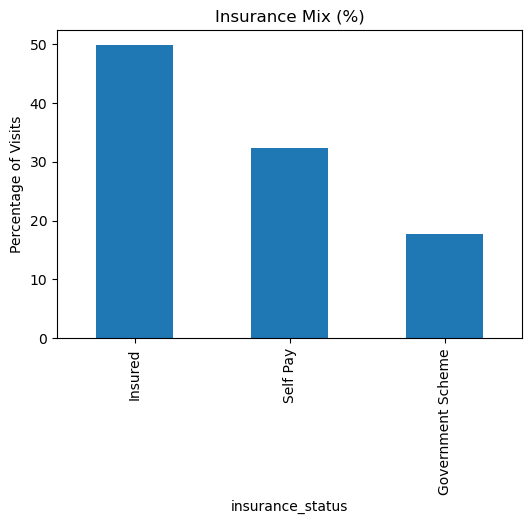

In [106]:
plt.figure(figsize=(6,4))
insurance_analysis.plot(kind='bar')
plt.title('Insurance Mix (%)')
plt.ylabel('Percentage of Visits')
plt.show()


### Observation
**Insured** is the largest payer group, representing about **49.9%** of visits.

### Insight
Hospital finance is strongly influenced by payer mix.

### Business Recommendation
Track revenue, pending payments and patient contribution separately by insurance category.


## Analysis 4 - How serious is the waiting-time problem?


In [107]:
print(df['waiting_time_minutes'].describe().round(2))


count    12000.00
mean        45.39
std         19.07
min          5.00
25%         34.00
50%         44.50
75%         55.00
max        244.00
Name: waiting_time_minutes, dtype: float64


In [108]:
244/60

4.066666666666666

In [109]:
wait_percentage = (
    df['wait_band']
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

display(wait_percentage)

wait_band
41-60    45.8
21-40    33.5
60+      14.5
<=20      6.2
Name: proportion, dtype: float64

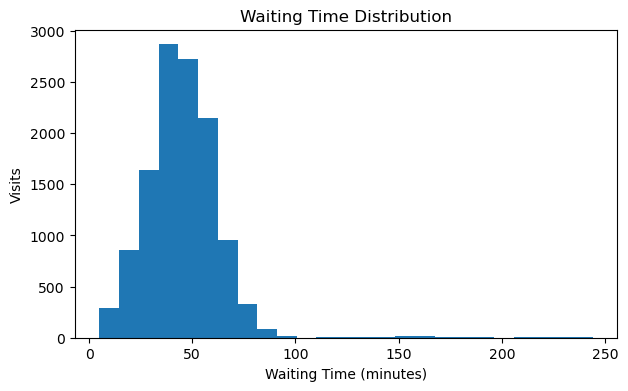

In [110]:
plt.figure(figsize=(7,4))
plt.hist(df['waiting_time_minutes'], bins=25)
plt.title('Waiting Time Distribution')
plt.xlabel('Waiting Time (minutes)')
plt.ylabel('Visits')
plt.show()


### Observation
Average waiting time is **45.4 minutes** and median waiting time is **44.5 minutes**.  
Approximately **15.2%** of visits wait more than 60 minutes.

### Insight
The waiting-time problem is not limited to a few unusual cases; a noticeable share of patients experience long waits.

### Business Recommendation
Management should track both **average waiting time** and **percentage of visits above 60 minutes**.


## Analysis 5 - Which city contributes the most hospital visits?


In [94]:
city_analysis = df['city'].value_counts()
display(city_analysis)

city
Hyderabad       5225
Secunderabad    2040
Warangal        1780
Karimnagar      1523
Nizamabad       1308
Unknown          124
Name: count, dtype: int64

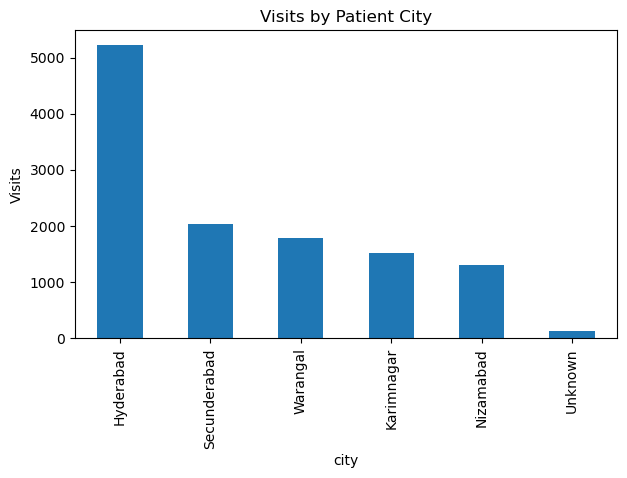

In [95]:
plt.figure(figsize=(7,4))
city_analysis.head(6).plot(kind='bar')
plt.title('Visits by Patient City')
plt.ylabel('Visits')
plt.show()


### Observation
**Hyderabad** contributes the highest number of visits at approximately **5,225 visits**.

### Insight
The hospital has a strong patient concentration in this market.

### Business Recommendation
Use city-level demand information for outreach clinics, marketing and future service expansion decisions.


# PART B - BIVARIATE ANALYSIS

Bivariate analysis compares **two variables** to understand how one business factor changes with another.


## Analysis 6 - Which department has the longest waiting time?


In [96]:
department_wait = (
    df.groupby('department')['waiting_time_minutes']
      .agg(['count','mean','median'])
      .round(2)
      .sort_values('mean', ascending=False)
)

display(department_wait)

,count,mean,median
department,,,
Cardiology,1914,58.88,58.0
General Medicine,3535,49.79,49.0
Pulmonology,1631,44.36,44.0
Orthopedics,1979,40.36,40.0
Gynecology,1489,37.05,36.0
Pediatrics,1452,33.43,33.0


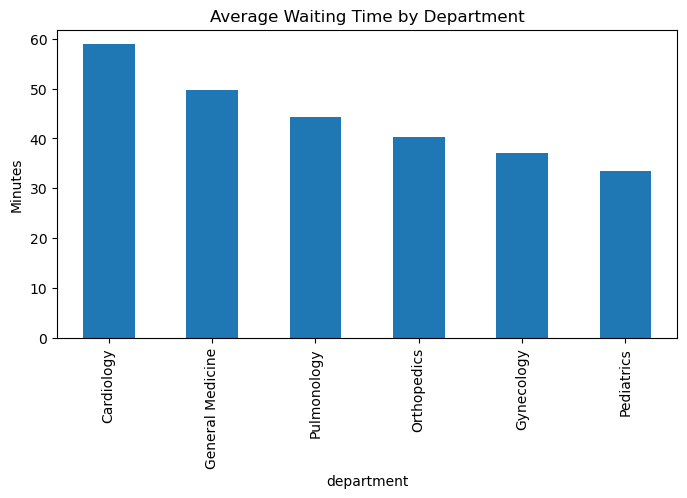

In [97]:
plt.figure(figsize=(8,4))
department_wait['mean'].plot(kind='bar')
plt.title('Average Waiting Time by Department')
plt.ylabel('Minutes')
plt.show()

### Observation
**Cardiology** has the highest average waiting time at about **58.9 minutes**.

### Insight
This department is a clear operational bottleneck compared with the other departments.

### Business Recommendation
Review appointment scheduling, doctor availability and registration flow specifically for **Cardiology**.


## Analysis 7 - Which department handles the highest patient volume?


In [98]:
department_volume = (
    df['department']
    .value_counts()
)

display(department_volume)

department
General Medicine    3535
Orthopedics         1979
Cardiology          1914
Pulmonology         1631
Gynecology          1489
Pediatrics          1452
Name: count, dtype: int64

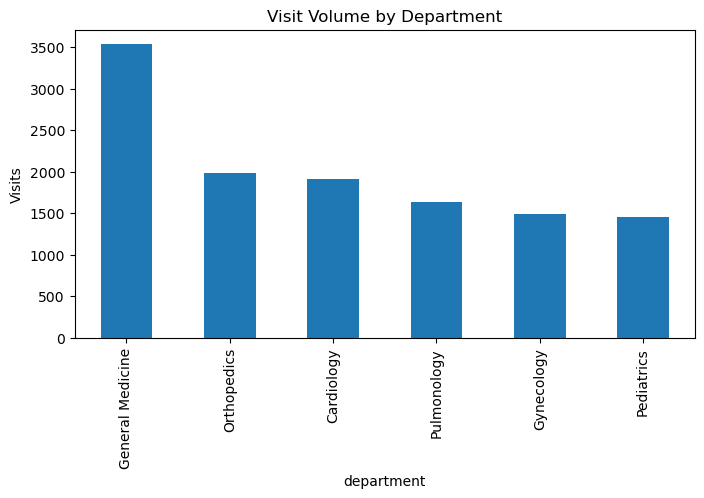

In [99]:
plt.figure(figsize=(8,4))
department_volume.plot(kind='bar')
plt.title('Visit Volume by Department')
plt.ylabel('Visits')
plt.show()


### Observation
**General Medicine** handles the highest volume with around **3,535 visits**.

### Insight
High patient volume does not automatically mean poor performance, but it places greater pressure on staffing and queue management.

### Business Recommendation
Use department volume together with waiting time when deciding staffing priorities.


## Analysis 8 - Does waiting time affect satisfaction?


In [100]:
waiting_satisfaction = (
    df.groupby('wait_band', observed=False)['satisfaction_score']
      .mean()
      .round(2)
)

display(waiting_satisfaction)

wait_band
<=20     4.76
21-40    4.56
41-60    4.33
60+      4.03
Name: satisfaction_score, dtype: float64

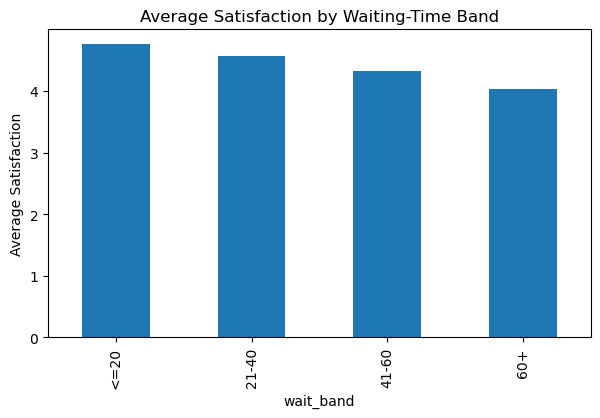

In [101]:
plt.figure(figsize=(7,4))
waiting_satisfaction.plot(kind='bar')
plt.title('Average Satisfaction by Waiting-Time Band')
plt.ylabel('Average Satisfaction')
plt.show()


### Observation
Patients waiting **20 minutes or less** have average satisfaction of about **4.76/5**, while patients waiting **more than 60 minutes** average about **4.03/5**.

### Insight
Patient experience declines clearly as waiting time increases.

### Business Recommendation
Treat long waiting time as a patient-experience issue, not only an operations issue. Prioritize reducing the 60+ minute group.


## Analysis 9 - Which insurance group pays the most from their own pocket?


In [102]:
insurance_payment = (
    df.groupby('insurance_status')
      .agg(avg_bill=('bill_amount','mean'),
           avg_patient_paid=('patient_paid_amount','mean'),
          avg_out_of_pocket_pct=('out_of_pocket_pct','mean')
      )
      .round(2)
)

display(insurance_payment)


,avg_bill,avg_patient_paid,avg_out_of_pocket_pct
insurance_status,,,
Government Scheme,6419.41,1134.01,17.89
Insured,6800.39,2104.44,31.55
Self Pay,6326.12,6308.01,99.91


### Observation
**Self Pay** patients have the highest average out-of-pocket share at approximately **99.9%**.

### Insight
These patients face the greatest direct financial burden.

### Business Recommendation
Provide cost estimates, payment counselling and installment options for high out-of-pocket groups.


## Analysis 10 - Which visit type is the most expensive?


In [103]:
visit_type_billing = (
    df.groupby('visit_type')
      .agg(
          visits=('visit_id','count'),
          average_bill=('bill_amount','mean'),
          total_revenue=('bill_amount','sum')
      )
      .round(2)
)

display(visit_type_billing)

,visits,average_bill,total_revenue
visit_type,,,
Emergency,2192,4723.14,10353122.15
Inpatient,1718,28640.87,49205013.45
OPD,8090,2397.32,19394352.69


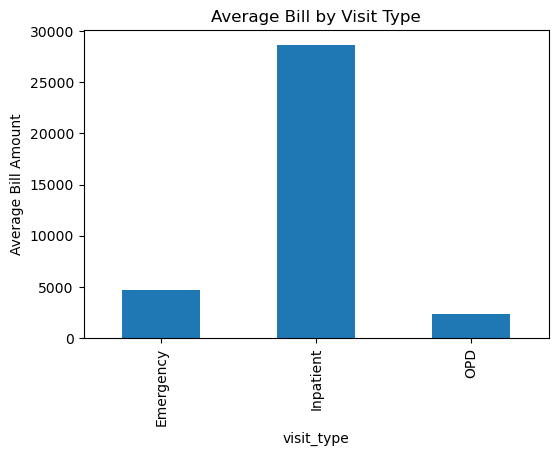

In [104]:
plt.figure(figsize=(6,4))
visit_type_billing['average_bill'].plot(kind='bar')
plt.title('Average Bill by Visit Type')
plt.ylabel('Average Bill Amount')
plt.show()


### Observation
**Inpatient** visits have the highest average bill at approximately **₹28,641** per visit.

### Insight
Inpatient care creates much higher financial value per visit than OPD or Emergency.

### Business Recommendation
Analyze inpatient capacity, length of stay and payer mix separately because inpatient economics are very different from OPD.


## Analysis 11 - Which age group and chronic condition combination creates the highest chronic-care demand?


In [33]:
age_chronic = (
    df[df['chronic_condition'] != 'None']
    .groupby(['age_group','chronic_condition'], observed=False)['patient_id']
    .nunique()
    .sort_values(ascending=False)
)

display(age_chronic.head(15))


age_group  chronic_condition
60+        Hypertension         235
46-60      Hypertension         226
           Diabetes             204
60+        Diabetes             171
31-45      Diabetes             153
           Hypertension         145
           Asthma               102
46-60      Cardiac               96
60+        Cardiac               95
46-60      Asthma                86
           Thyroid               83
18-30      Diabetes              68
31-45      Thyroid               55
18-30      Hypertension          50
31-45      Cardiac               48
Name: patient_id, dtype: int64

### Observation
The largest chronic-care segment is **Hypertension among the 60+ age group**, with about **235 unique patients**.

### Insight
Chronic-care demand is concentrated in particular age-condition combinations rather than being evenly distributed.

### Business Recommendation
Develop targeted follow-up and screening programs for the highest-demand chronic segments.


# PART C - MULTIVARIATE & DIAGNOSTIC ANALYSIS

Now we combine multiple factors to answer more realistic management questions.


## Analysis 12 - Which department and visit-type combination has the most serious waiting problem?


In [34]:
department_type = (
    df.groupby(['department','visit_type'])
      .agg(
          visits=('visit_id','count'),
          avg_wait=('waiting_time_minutes','mean'),
          avg_satisfaction=('satisfaction_score','mean')
      )
      .round(2)
      .sort_values(['avg_wait','visits'], ascending=[False,False])
)

display(department_type.head(15))


visits  avg_wait  avg_satisfaction
department       visit_type                                    
Cardiology       OPD           1315     61.56              4.18
                 Inpatient      262     57.17              4.22
General Medicine OPD           2373     52.31              4.30
Cardiology       Emergency      337     49.73              4.35
General Medicine Inpatient      488     47.94              4.35
Pulmonology      OPD           1126     46.70              4.36
Orthopedics      OPD           1329     43.16              4.42
Pulmonology      Inpatient      228     42.89              4.43
General Medicine Emergency      674     42.26              4.41
Gynecology       OPD            976     39.97              4.47
Orthopedics      Inpatient      302     39.58              4.49
Pediatrics       OPD            971     36.45              4.51
Pulmonology      Emergency      277     36.07              4.51
Gynecology       Inpatient      229     34.71              4.49
Pediatrics       Inpatient      209     32.00              4.56

### Observation
The most serious combination is **Cardiology - OPD**, with an average wait of around **61.6 minutes** and satisfaction around **4.18/5**.

### Insight
The problem is more specific than saying “Cardiology is slow.” The operational pressure is concentrated in a particular service type.

### Business Recommendation
Start improvement work with the exact department-service combination rather than applying the same solution to the whole hospital.


## Analysis 13 - When does hospital demand peak?


visit_day
Wednesday    1795
Sunday       1727
Monday       1720
Tuesday      1705
Thursday     1696
Saturday     1679
Friday       1678
Name: count, dtype: int64

visit_hour
13    1461
12    1456
11    1333
14    1321
10    1113
15    1095
9      862
16     841
Name: count, dtype: int64

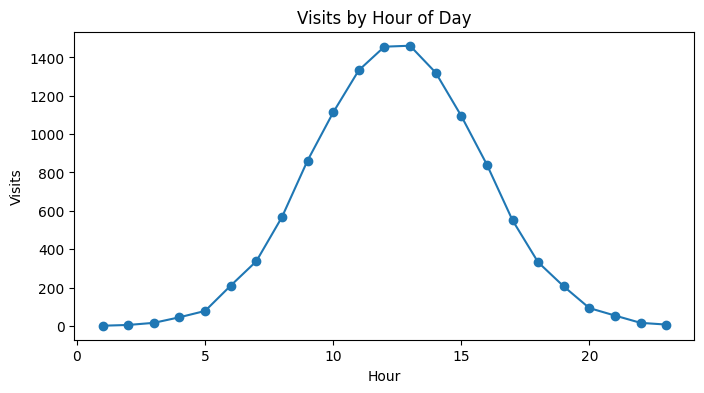

In [35]:
hour_analysis = df['visit_hour'].value_counts().sort_index()
day_analysis = df['visit_day'].value_counts()

display(day_analysis)
display(hour_analysis.sort_values(ascending=False).head(8))

plt.figure(figsize=(8,4))
hour_analysis.plot(kind='line', marker='o')
plt.title('Visits by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Visits')
plt.show()


### Observation
The busiest day is **Wednesday** and the busiest hour is approximately **13:00**.

### Insight
Hospital demand is concentrated at predictable times.

### Business Recommendation
Increase registration, nursing and consultation support around the recurring peak period instead of increasing staffing equally across all hours.


## Analysis 14 - How important are repeat patients?


In [36]:
repeat_analysis = (
    df.groupby('repeat_patient')
      .agg(
          unique_patients=('patient_id','nunique'),
          total_visits=('visit_id','count'),
          avg_bill=('bill_amount','mean'),
          avg_satisfaction=('satisfaction_score','mean')
      )
      .round(2)
)

display(repeat_analysis)


,unique_patients,total_visits,avg_bill,avg_satisfaction
repeat_patient,,,,
Repeat,3186,11383,6564.48,4.39
Single Visit,617,617,6854.11,4.38


### Observation
Approximately **83.8%** of unique patients have more than one visit during the analysis period.

### Insight
Repeat utilization is a major part of hospital demand.

### Business Recommendation
Do not treat every repeat visit as a negative outcome. Separate chronic-care follow-up from potentially avoidable repeat visits by diagnosis and chronic condition.


## Analysis 15 - Is the satisfaction difference between low-wait and high-wait patients statistically meaningful?


In [37]:
low_wait = df.loc[
    df['waiting_time_minutes'] <= 40,
    'satisfaction_score'
]

high_wait = df.loc[
    df['waiting_time_minutes'] > 60,
    'satisfaction_score'
]

t_stat, p_value = stats.ttest_ind(
    low_wait,
    high_wait,
    equal_var=False
)

print('Low-wait average satisfaction:', round(low_wait.mean(), 2))
print('High-wait average satisfaction:', round(high_wait.mean(), 2))
print('P-value:', p_value)


Low-wait average satisfaction: 4.59
High-wait average satisfaction: 4.03
P-value: 0.0


### Observation
Low-wait patients average about **4.59/5**, while high-wait patients average about **4.03/5**.  
The p-value is extremely small (**p < 0.001**).

### Insight
The satisfaction difference between low-wait and high-wait patients is statistically significant in this dataset.

### Business Recommendation
Waiting-time reduction can be treated as a measurable patient-experience improvement initiative.

### Success Metric
Reduce 60+ minute waits and track whether satisfaction improves at the same time.


# PART D - FINAL MANAGEMENT STORY

## What the Analysis Tells Us

1. Patient demand is concentrated in specific age groups and chronic conditions.
2. Cardiology has the strongest waiting-time pressure.
3. General Medicine handles the highest overall visit volume.
4. Satisfaction decreases as waiting time increases.
5. Self-pay patients carry almost the entire bill themselves.
6. Inpatient services have the highest average billing value.
7. Demand peaks at identifiable days and hours.
8. Repeat patients represent a major part of utilization.

## Final Business Recommendations

### 1. Improve Cardiology OPD Flow
Review doctor scheduling, appointment slots and patient registration flow.

### 2. Create a Waiting-Time KPI
Track:
- Average waiting time
- Median waiting time
- Percentage above 60 minutes

### 3. Align Staffing With Demand
Use hourly and day-level visit patterns to plan staffing.

### 4. Improve Chronic-Care Follow-Up
Create focused follow-up workflows for high-utilization age-condition groups.

### 5. Reduce Patient Financial Stress
Provide better cost communication and payment options for self-pay patients.

### 6. Monitor Patient Experience Together With Operations
Do not report satisfaction separately from waiting-time performance.


# Interview-Ready Project Explanation

> “I worked on an end-to-end healthcare analytics project using three tables: Patients, Visits and Billing. I first understood the business problems and audited data quality. For missing values, I did not blindly use mean or median. I used chronic condition to fill invalid age, age group to fill BMI, diagnosis to support department imputation, department plus visit type for waiting time, waiting band for satisfaction, and payer rules for insurance coverage. After cleaning and merging the data, I performed univariate, bivariate and multivariate analysis. For every analysis I first asked a business question, generated a table or visualization, observed the actual result, converted it into a business insight, and then recommended an action. I also used a simple t-test to validate the relationship between waiting time and satisfaction.”
